<a href="https://colab.research.google.com/github/chandumonubol/DeepLearning-and-Neural-Network/blob/main/RNN_Hands_On.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on: Movie Review Sentiment Analysis Using RNN

Consider an online movie review platform that receives thousands of customer reviews. The platform wants to automatically identify whether a review expresses a positive or negative opinion. Your task is to develop a sentiment classification model using a Simple Recurrent Neural Network (RNN) and the IMDb Movie Reviews dataset available in TensorFlow/Keras.


The dataset contains 50,000 movie reviews, divided into 25,000 training reviews and 25,000 testing reviews, with 25,000 positive and 25,000 negative reviews overall. Each review is associated with a sentiment label (1 – Positive, 0 – Negative).

The Keras version of the dataset is already preprocessed, with reviews represented as numerical word sequences using the 10,000 most frequent words.

 Apply padding to make all review sequences 200 positions long, use an Embedding layer to convert word IDs into 32-dimensional vectors, and build a Simple RNN model to classify the reviews. Train the model, evaluate its performance on the test dataset, and visualize the training and validation accuracy.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb

In [ ]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)

#num_words = 10000 --> limits the vocabulary to the 10k most frequent words.

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#explore the dataset

print("training reviews: ",len(X_train))
print("testing reviews: ",len(X_test))

print("first review is : ", X_train[0])
print("Label of first review is : ", y_train[0])

training reviews:  25000
testing reviews:  25000
first review is :  [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 1

#PADDING

- if we want to process all the review together in batches, we need to make theor sequence length equal

- two types of padding
#Pre padding - add zeros at the beginning
#Post padding - add zeros at the end

original 1 - [10,20,30]
original  2 - [1,2,3,4,5,6,7,8,9,10]

pre padding  - [0,0,0,0,0,0,0,10,20,30]
post padding - [10,20,30,0,0,0,0,0,0,0]
original  2 - [1,2,3,4,5,6,7,8,9,10]

#mask_zero = True --> in our embedding layers it ignores zero-  especially at post padding.

In [ ]:
#padding
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
max_length = 200

X_train = pad_sequences(X_train, maxlen = max_length,padding = "post",truncating= 'post' )
X_test = pad_sequences(X_test, maxlen = max_length,padding = "post" , truncating= 'post')

In [ ]:
print(X_train.shape)
print(X_test.shape)

(25000, 200)
(25000, 200)


In [ ]:
#Build the RNN model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

In [ ]:
model = Sequential([
    Embedding(input_dim = 10000, output_dim= 32,mask_zero = True),
    SimpleRNN(32),
    Dense(1,activation = 'sigmoid')
])

In [ ]:
#compile the model
model.compile(optimizer= 'adam',loss  = 'binary_crossentropy',metrics = ['accuracy'])

Adam -Momentum +adaptive learning first momentum - moving average if gradients adam considers previous gradients to determine the direction of weight updates

adaptive learning - adam adjusts the learning rate for individual paramenters based on the history of gradients

binary_crossentropy - loss function imdb - positive/negative [yes/no] uses for binary classification

categorical cross entropy - used for multiclass classification

In [ ]:
#train
x = model.fit(
    X_train,
    y_train,
    epochs = 5,
    batch_size = 128,
    validation_split = 0.2
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - accuracy: 0.6904 - loss: 0.5683 - val_accuracy: 0.8100 - val_loss: 0.4562
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - accuracy: 0.8403 - loss: 0.3837 - val_accuracy: 0.7754 - val_loss: 0.4790
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - accuracy: 0.8750 - loss: 0.3160 - val_accuracy: 0.8514 - val_loss: 0.3501
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 22s 117ms/step - accuracy: 0.9270 - loss: 0.2028 - val_accuracy: 0.8530 - val_loss: 0.3717
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - accuracy: 0.9606 - loss: 0.1246 - val_accuracy: 0.8446 - val_loss: 0.3968


In [ ]:
#evaluate
test_loss,test_accuracy = model.evaluate(X_test,y_test)
print(test_loss)
print(test_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.8272 - loss: 0.4365
0.4365122318267822
0.8271600008010864


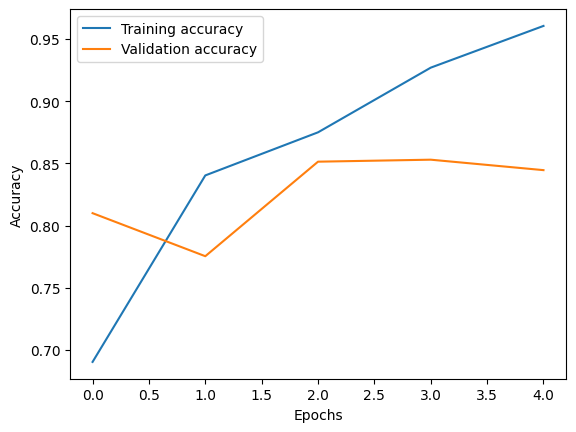

In [ ]:
#visualize
plt.plot(x.history['accuracy'],label = "Training accuracy")
plt.plot(x.history['val_accuracy'],label = 'Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

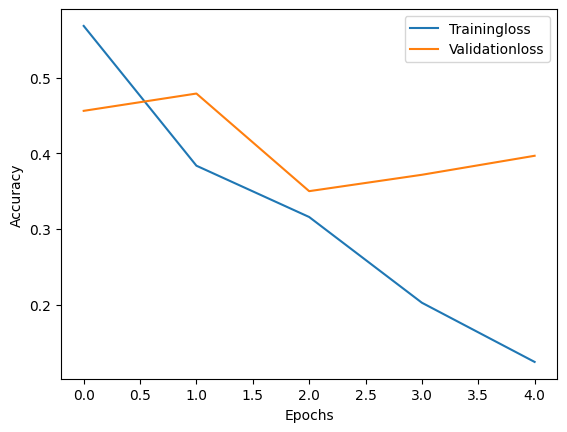

In [ ]:
#visualize
plt.plot(x.history['loss'],label = "Trainingloss")
plt.plot(x.history['val_loss'],label = 'Validationloss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

#Import libraries

#load IMDB Dataset

#explore the datset

#applied padding and truncate

#embedding layer

#SimpleRNN layer

#Dense Layer [activation - sigmoid]

#Compile the model [optimizer,loss,metrics]

#Train the model

#Evaluate the model

#visualize the model(optional)